In [1]:
import os
import json
import random
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from scipy.ndimage import (
    binary_dilation,
    binary_erosion,
    distance_transform_edt
)

from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
from scipy.ndimage import maximum_filter, minimum_filter
from sklearn.model_selection import KFold
import hashlib

TensorFlow: 2.16.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
YEAR = 2020
DATA_ROOT = None  # Optional exact labeled training directory for the selected year
SEED = 42
N_FOLDS = 5
FOLDS = [0]  # list(range(N_FOLDS)) for the full benchmark
WT_LOSSES = ["dice"]  # ["dice", "dice_boundary"] to compare WT objectives
AUDIT_ONLY = False
CACHE_IMAGES = False  # True uses more disk to avoid repeated MRI preprocessing
EPOCHS = 10
BATCH_SIZE = 1
LEARNING_RATE = 2e-5
DROPOUT = 0.20
TAU, EPSILON = 0.50, 0.10
BOUNDARY_WEIGHT = 0.2
MODES = ["hard", "fixed3", "fixed5", "adaptive"]
TARGET_SHAPE = (128, 128, 128)
MODALITIES = ["t1", "t1ce", "t2", "flair"]
OUTPUT = Path("/kaggle/working/cps_lcbts_cv")
mixed_precision.set_global_policy("mixed_float16")
tf.keras.utils.set_random_seed(SEED)

In [ ]:
def find_modality_file(
    case_dir,
    suffix
):

    case_dir = Path(
        case_dir
    )

    standard_matches = (
        list(
            case_dir.glob(
                f"*_{suffix}.nii"
            )
        )
        +
        list(
            case_dir.glob(
                f"*_{suffix}.nii.gz"
            )
        )
    )

    if len(
        standard_matches
    ) == 1:

        return (
            standard_matches[0]
        )

    if suffix == "seg":

        alternative_matches = (

            list(
                case_dir.glob(
                    "*Segm.nii"
                )
            )

            +

            list(
                case_dir.glob(
                    "*Segm.nii.gz"
                )
            )

            +

            list(
                case_dir.glob(
                    "*segm.nii"
                )
            )

            +

            list(
                case_dir.glob(
                    "*segm.nii.gz"
                )
            )
        )

        if len(
            alternative_matches
        ) == 1:

            return (
                alternative_matches[0]
            )

    raise FileNotFoundError(
        f"Could not find "
        f"{suffix} in "
        f"{case_dir}"
    )

In [2]:
def discover_cases(year, root=None):
    if year not in (2020, 2021):
        raise ValueError("Select BraTS 2020 or 2021 (ET label 4).")
    root = Path(root or "/kaggle/input")
    if not root.is_dir():
        raise FileNotFoundError(root)
    prefix = "brats20_training_" if year == 2020 else "brats2021_"
    cases = {}
    for folder, _, files in os.walk(root):
        case = Path(folder)
        if not case.name.lower().startswith(prefix) or not any(
            f.lower().endswith(("seg.nii", "seg.nii.gz", "segm.nii", "segm.nii.gz")) for f in files
        ):
            continue
        for modality in [*MODALITIES, "seg"]:
            find_modality_file(case, modality)
        if case.name in cases:
            raise ValueError(f"Duplicate patient {case.name}. Set DATA_ROOT to one cohort.")
        cases[case.name] = case
    if len(cases) < N_FOLDS:
        raise ValueError(f"Found {len(cases)} labeled patients for {year} under {root}. Check YEAR and DATA_ROOT.")
    return dict(sorted(cases.items()))

cases = discover_cases(YEAR, DATA_ROOT)
print("Labeled patients:", len(cases))

Labeled patients: 369


In [ ]:
def crop_brats(volume, target_shape=(128, 128, 128)):

    target_x, target_y, target_z = target_shape

    x, y, z = volume.shape

    start_x = (x - target_x) // 2
    start_y = (y - target_y) // 2

    start_z = 15

    cropped = volume[
        start_x:start_x + target_x,
        start_y:start_y + target_y,
        start_z:start_z + target_z
    ]

    if cropped.shape != target_shape:
        raise ValueError(
            f"Unexpected crop shape {cropped.shape}"
        )

    return cropped

In [ ]:
def zscore_normalize(volume, eps=1e-8):

    volume = volume.astype(np.float32)

    mean = np.mean(volume)
    std = np.std(volume)

    normalized = (
        volume - mean
    ) / (std + eps)

    return normalized

In [ ]:
def create_binary_masks(seg):

    wt = (seg > 0).astype(np.uint8)

    tc = np.isin(
        seg,
        [1, 4]
    ).astype(np.uint8)

    et = (
        seg == 4
    ).astype(np.uint8)

    return wt, tc, et

In [ ]:
def preprocess_patient(case_dir):

    case_dir = Path(case_dir)

    channels = []

    for modality in MODALITIES:

        file_path = find_modality_file(
            case_dir,
            modality
        )

        volume = nib.load(
            file_path
        ).get_fdata(
            dtype=np.float32
        )

        volume = crop_brats(volume)

        volume = zscore_normalize(
            volume
        )

        channels.append(volume)

    X = np.stack(
        channels,
        axis=-1
    ).astype(np.float32)

    seg_path = find_modality_file(
        case_dir,
        "seg"
    )

    seg = nib.load(
        seg_path
    ).get_fdata()

    seg = crop_brats(seg)

    seg = seg.astype(np.uint8)

    wt, tc, et = create_binary_masks(seg)

    return X, wt, tc, et

In [ ]:
def patient_arrays(patient):
    path = OUTPUT / str(YEAR) / "crop128_v1" / f"{patient}.npz"
    if CACHE_IMAGES and path.exists():
        with np.load(path) as a:
            return a["X"].astype(np.float32), a["wt"], a["tc"], a["et"]
    X, wt, tc, et = preprocess_patient(cases[patient])
    # Match the original notebook's stored MRI precision on both loading paths.
    X = X.astype(np.float16)
    if CACHE_IMAGES:
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_suffix(".tmp.npz")
        np.savez_compressed(tmp, X=X, wt=wt, tc=tc, et=et)
        tmp.replace(path)
    return X.astype(np.float32), wt, tc, et

## Original segmentation network and WT boundary objective

In [ ]:
SMOOTH = 1.0

In [ ]:
def dice_coefficient(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    axes = (
        1,
        2,
        3,
        4
    )

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=axes
    )

    denominator = (

        tf.reduce_sum(
            tf.square(y_true),
            axis=axes
        )

        +

        tf.reduce_sum(
            tf.square(y_pred),
            axis=axes
        )
    )

    dice = (

        2.0 * intersection
        + SMOOTH

    ) / (

        denominator
        + SMOOTH
    )

    return tf.reduce_mean(
        dice
    )

In [ ]:
def dice_loss(
    y_true,
    y_pred
):

    return (
        1.0
        -
        dice_coefficient(
            y_true,
            y_pred
        )
    )

In [ ]:
class InstanceNormalization(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        epsilon=1e-5,
        **kwargs
    ):

        super().__init__(
            **kwargs
        )

        self.epsilon = epsilon

    def build(
        self,
        input_shape
    ):

        channels = int(
            input_shape[-1]
        )

        self.gamma = self.add_weight(
            name="gamma",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )

        self.beta = self.add_weight(
            name="beta",
            shape=(channels,),
            initializer="zeros",
            trainable=True
        )

    def call(
        self,
        inputs
    ):

        x = tf.cast(
            inputs,
            tf.float32
        )

        mean, variance = tf.nn.moments(
            x,
            axes=[
                1,
                2,
                3
            ],
            keepdims=True
        )

        x = (
            x - mean
        ) / tf.sqrt(
            variance
            +
            self.epsilon
        )

        x = (
            x * tf.cast(self.gamma, tf.float32)
            +
            self.beta
        )

        return tf.cast(
            x,
            inputs.dtype
        )

In [ ]:
def conv_block(
    x,
    filters,
    kernel_size=3,
    name="conv"
):

    x = layers.Conv3D(
        filters,
        kernel_size,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{name}_conv"
    )(x)

    x = InstanceNormalization(
        name=f"{name}_in"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01,
        name=f"{name}_act"
    )(x)

    return x

In [ ]:
def encoder_block(
    x,
    filters,
    pooling=True,
    name="EB"
):

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_1"
    )

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_2"
    )

    skip = x

    if pooling:

        x = layers.MaxPool3D(
            pool_size=2,
            name=f"{name}_pool"
        )(x)

        x = layers.Dropout(
            DROPOUT,
            name=f"{name}_dropout"
        )(x)

    return x, skip

In [ ]:
def lateral_block(
    x,
    filters=64,
    name="LB"
):

    x = layers.Conv3D(
        filters,
        kernel_size=1,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{name}_conv"
    )(x)

    x = InstanceNormalization(
        name=f"{name}_in"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01
    )(x)

    return x

In [ ]:
def decoder_block(
    x,
    filters=64,
    name="DB"
):

    x = layers.Conv3DTranspose(
        filters,
        kernel_size=2,
        strides=2,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{name}_up"
    )(x)

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_conv"
    )

    return x

In [ ]:
def merge_block(
    lateral,
    decoder,
    filters=64,
    name="MB"
):

    x = layers.Add(
        name=f"{name}_add"
    )([
        lateral,
        decoder
    ])

    x = layers.Dropout(
        DROPOUT,
        name=f"{name}_dropout"
    )(x)

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_conv"
    )

    return x

In [ ]:
def build_lcbts_subnetwork(
    name="LCBTS"
):

    inputs = keras.Input(
        shape=(
            128,
            128,
            128,
            4
        ),
        name="input"
    )

    # Encoder
    x, skip1 = encoder_block(
        inputs,
        32,
        True,
        "EB1"
    )

    x, skip2 = encoder_block(
        x,
        64,
        True,
        "EB2"
    )

    x, skip3 = encoder_block(
        x,
        64,
        True,
        "EB3"
    )

    x, _ = encoder_block(
        x,
        64,
        False,
        "EB4"
    )

    # Decoder level 3
    lateral3 = lateral_block(
        skip3,
        64,
        "LB3"
    )

    decoder3 = decoder_block(
        x,
        64,
        "DB3"
    )

    x = merge_block(
        lateral3,
        decoder3,
        64,
        "MB3"
    )

    # Decoder level 2
    lateral2 = lateral_block(
        skip2,
        64,
        "LB2"
    )

    decoder2 = decoder_block(
        x,
        64,
        "DB2"
    )

    x = merge_block(
        lateral2,
        decoder2,
        64,
        "MB2"
    )

    # Decoder level 1
    lateral1 = lateral_block(
        skip1,
        64,
        "LB1"
    )

    decoder1 = decoder_block(
        x,
        64,
        "DB1"
    )

    x = merge_block(
        lateral1,
        decoder1,
        64,
        "MB1"
    )

    # Final feature block
    x = layers.Conv3D(
        64,
        3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01
    )(x)

    x = layers.Conv3D(
        32,
        3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01
    )(x)

    outputs = layers.Conv3D(
        1,
        kernel_size=1,
        activation="sigmoid",
        dtype="float32",
        name="prediction"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name=name
    )

In [ ]:
def soft_boundary(mask):
    # Inner edge using a 3x3x3 erosion; gradients flow through the predicted edge.
    mask = tf.cast(mask, tf.float32)
    eroded = -tf.nn.max_pool3d(-mask, ksize=3, strides=1, padding="SAME")
    return mask - eroded

def dice_boundary_loss(y, p):
    return dice_loss(y, p) + BOUNDARY_WEIGHT * dice_loss(soft_boundary(y), soft_boundary(p))

## Probability-weighted margin and validation audit

In [ ]:
def guidance_maps(p, mode):
    """Return MRI multiplier and the explicit safety region (before residual guidance)."""
    p = np.asarray(p, dtype=np.float32)
    hard = p >= TAU
    if mode == "hard":
        return hard.astype(np.float32), hard
    if mode not in ("fixed3", "fixed5", "adaptive"):
        raise ValueError(mode)
    near = maximum_filter(hard, size=3, mode="constant")
    if mode == "fixed3":
        support = near
        floor = TAU * support
    elif mode == "fixed5":
        support = maximum_filter(hard, size=5, mode="constant")
        floor = TAU * support
    else:
        edge = hard & ~minimum_filter(hard, size=3, mode="constant")
        q = np.clip(p, 1e-6, 1 - 1e-6)
        entropy = -(q * np.log2(q) + (1-q) * np.log2(1-q))
        confidence_weight = maximum_filter(np.where(edge, entropy, 0), size=5, mode="constant")
        outer = ~near & (confidence_weight >= 0.75)
        support = near | outer
        floor = np.where(near, TAU, np.where(outer, TAU * confidence_weight, 0))
    return (EPSILON + (1-EPSILON) * np.maximum(p, floor)).astype(np.float32), support

def audit_counts(p, wt, tc, et, mode):
    hard = p >= TAU
    _, support = guidance_maps(p, mode)
    added = support & ~hard
    return dict(missed_tc=int((tc.astype(bool) & ~hard).sum()),
                missed_et=int((et.astype(bool) & ~hard).sum()),
                covered_tc=int((tc.astype(bool) & added).sum()),
                covered_et=int((et.astype(bool) & added).sum()),
                added_background=int((added & ~wt.astype(bool)).sum()))

In [ ]:
def check_margins():
    p = np.zeros((9, 9, 9), dtype=np.float32)
    for value, expected in [(0.99, 27), (0.51, 125)]:
        p[4, 4, 4] = value
        g, s = guidance_maps(p, "adaptive")
        assert s.sum() == expected and np.isfinite(g).all()
        assert guidance_maps(p, "fixed3")[1].sum() == 27
        assert guidance_maps(p, "fixed5")[1].sum() == 125
    assert not guidance_maps(np.zeros_like(p), "adaptive")[1].any()
check_margins()

In [ ]:
def dice_numpy(
    ground_truth,
    prediction
):

    ground_truth = (
        ground_truth.astype(bool)
    )

    prediction = (
        prediction.astype(bool)
    )

    if (
        not ground_truth.any()
        and
        not prediction.any()
    ):
        return 1.0

    intersection = (
        np.logical_and(
            ground_truth,
            prediction
        ).sum()
    )

    return (
        2.0 * intersection
    ) / (
        ground_truth.sum()
        +
        prediction.sum()
        +
        1e-8
    )

In [ ]:
def hd95_numpy(
    ground_truth,
    prediction,
    spacing=(1.0, 1.0, 1.0)
):

    ground_truth = (
        ground_truth.astype(bool)
    )

    prediction = (
        prediction.astype(bool)
    )

    if (
        not ground_truth.any()
        and
        not prediction.any()
    ):
        return 0.0

    if (
        not ground_truth.any()
        or
        not prediction.any()
    ):
        return np.nan

    gt_surface = np.logical_xor(
        ground_truth,
        binary_erosion(
            ground_truth
        )
    )

    pred_surface = np.logical_xor(
        prediction,
        binary_erosion(
            prediction
        )
    )

    distance_to_prediction = (
        distance_transform_edt(
            ~pred_surface,
            sampling=spacing
        )
    )

    distance_to_gt = (
        distance_transform_edt(
            ~gt_surface,
            sampling=spacing
        )
    )

    d1 = distance_to_prediction[
        gt_surface
    ]

    d2 = distance_to_gt[
        pred_surface
    ]

    return float(
        max(
            np.percentile(
                d1,
                95
            ),
            np.percentile(
                d2,
                95
            )
        )
    )

## Patient folds, checkpoint selection and evaluation
Each outer test patient is excluded from both fitting and checkpoint selection. Each target uses matched initialization across guidance variants. Completed stages reuse validation-selected weights. Keep the output directory across sessions to reuse completed work. HD95 is in millimetres using the segmentation header spacing. An empty pair scores zero distance, and a one-sided empty prediction or reference has undefined HD95 and is counted separately.

In [ ]:
def patient_folds(ids):
    ids = np.array(sorted(ids))
    cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for fold, (dev, test) in enumerate(cv.split(ids)):
        train, val = train_test_split(ids[dev], test_size=0.125, random_state=SEED + fold)
        yield fold, dict(train=train.tolist(), val=val.tolist(), test=ids[test].tolist())

def probability(cache, patient):
    with np.load(cache / f"{patient}.npz") as data:
        return data["p"].astype(np.float32)

def dataset(ids, target, mode, cache, training, seed):
    index = {"wt": 1, "tc": 2, "et": 3}[target]
    def read(raw):
        patient = raw.decode()
        arrays = patient_arrays(patient)
        X = arrays[0]
        if mode:
            gain, _ = guidance_maps(probability(cache, patient), mode)
            X = X * gain[..., None]
        return X, arrays[index][..., None].astype(np.float32)
    def mapper(patient):
        X, y = tf.numpy_function(read, [patient], [tf.float32, tf.float32])
        return tf.ensure_shape(X, (*TARGET_SHAPE, 4)), tf.ensure_shape(y, (*TARGET_SHAPE, 1))
    ds = tf.data.Dataset.from_tensor_slices(ids)
    if training:
        ds = ds.shuffle(len(ids), seed=seed)
    return ds.map(mapper, num_parallel_calls=1).batch(BATCH_SIZE).prefetch(1)

def fit_stage(folder, split, target, mode, cache, objective, seed):
    folder.mkdir(parents=True, exist_ok=True)
    best = folder / "best.weights.h5"
    done = folder / "finished"
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_lcbts_subnetwork()
    if not done.exists():
        model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                      loss=dice_boundary_loss if objective == "dice_boundary" else dice_loss,
                      metrics=[dice_coefficient])
        history = model.fit(dataset(split["train"], target, mode, cache, True, seed),
                            validation_data=dataset(split["val"], target, mode, cache, False, seed),
                            epochs=EPOCHS, callbacks=[
                                keras.callbacks.ModelCheckpoint(str(best), monitor="val_dice_coefficient",
                                    mode="max", save_best_only=True, save_weights_only=True),
                                keras.callbacks.CSVLogger(str(folder / "training.csv"))])
        if not np.isfinite(history.history["val_dice_coefficient"]).all():
            raise ValueError(f"Nonfinite validation score in {folder}")
        done.touch()
    model.load_weights(best)
    return model

def write_csv(rows, path):
    tmp = path.with_suffix(".tmp.csv")
    pd.DataFrame(rows).to_csv(tmp, index=False)
    tmp.replace(path)

def measure(patient, gt, pred):
    spacing = nib.load(find_modality_file(cases[patient], "seg")).header.get_zooms()[:3]
    return dict(dice=dice_numpy(gt, pred), hd95_mm=hd95_numpy(gt, pred, spacing),
                one_empty=int(bool(gt.any()) != bool(pred.any())))

In [ ]:
def run_fold(folder, split, fold, objective):
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "split.json").write_text(json.dumps(split, indent=2))
    cache = folder / "probabilities"
    cache.mkdir(exist_ok=True)
    seed = SEED + 10 * fold
    wt_model = fit_stage(folder / "wt", split, "wt", None, cache, objective, seed)
    audit = []
    rows = []
    groups = ["val"] if AUDIT_ONLY else ["train", "val", "test"]
    for group in groups:
        for patient in split[group]:
            path = cache / f"{patient}.npz"
            if group == "train" and path.exists():
                continue
            X, wt, tc, et = patient_arrays(patient)
            if not path.exists():
                p = wt_model(X[None], training=False).numpy()[0, ..., 0]
                tmp = path.with_suffix(".tmp.npz")
                np.savez_compressed(tmp, p=p.astype(np.float32))
                tmp.replace(path)
            p = probability(cache, patient)
            if group == "val":
                for mode in MODES:
                    audit.append(dict(patient=patient, mode=mode, **audit_counts(p, wt, tc, et, mode)))
            elif group == "test":
                rows.append(dict(patient=patient, region="wt", mode="shared",
                                 **measure(patient, wt, p >= TAU)))
    del wt_model
    write_csv(audit, folder / "validation_margin_audit.csv")
    print(pd.DataFrame(audit).groupby("mode").sum(numeric_only=True))
    if AUDIT_ONLY:
        return
    for target, index in [("tc", 2), ("et", 3)]:
        for mode in MODES:
            stage = folder / f"{target}_{mode}"
            model = fit_stage(stage, split, target, mode, cache, "dice", seed + index)
            for patient in split["test"]:
                arrays = patient_arrays(patient)
                p = probability(cache, patient)
                gain, _ = guidance_maps(p, mode)
                pred = model((arrays[0] * gain[..., None])[None], training=False).numpy()[0,...,0] >= TAU
                gt = arrays[index].astype(bool)
                missed = gt & (p < TAU)
                rows.append(dict(patient=patient, region=target, mode=mode,
                                 missed=int(missed.sum()), recovered=int((missed & pred).sum()),
                                 **measure(patient, gt, pred)))
            del model
            gc.collect()
    write_csv(rows, folder / "test_patients.csv")
    # Once all downstream stages have finished, the probabilities are reproducible.
    for patient in sum(split.values(), []):
        (cache / f"{patient}.npz").unlink(missing_ok=True)

In [3]:
assert FOLDS and set(FOLDS) <= set(range(N_FOLDS))
assert WT_LOSSES and set(WT_LOSSES) <= {"dice", "dice_boundary"}
settings = dict(version=1, patients=list(cases), folds=N_FOLDS, seed=SEED, epochs=EPOCHS,
                batch=BATCH_SIZE, lr=LEARNING_RATE, dropout=DROPOUT, tau=TAU, epsilon=EPSILON,
                boundary_weight=BOUNDARY_WEIGHT, modes=MODES)
key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:12]
run = OUTPUT / str(YEAR) / key
run.mkdir(parents=True, exist_ok=True)
(run / "settings.json").write_text(json.dumps(settings, indent=2))
for fold, split in patient_folds(cases):
    if fold in FOLDS:
        for objective in WT_LOSSES:
            folder = run / objective / f"fold_{fold}"
            if not (folder / "test_patients.csv").exists():
                run_fold(folder, split, fold, objective)
print("Experiment outputs:", run)

Epoch 1/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 142s 485ms/step - dice_coefficient: 0.4123 - loss: 0.5877 - val_dice_coefficient: 0.6214 - val_loss: 0.3786
Epoch 2/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 121s 469ms/step - dice_coefficient: 0.7105 - loss: 0.2895 - val_dice_coefficient: 0.7842 - val_loss: 0.2158
Epoch 3/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 120s 466ms/step - dice_coefficient: 0.8012 - loss: 0.1988 - val_dice_coefficient: 0.8315 - val_loss: 0.1685
Epoch 4/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 121s 468ms/step - dice_coefficient: 0.8410 - loss: 0.1590 - val_dice_coefficient: 0.8540 - val_loss: 0.1460
Epoch 5/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 120s 466ms/step - dice_coefficient: 0.8615 - loss: 0.1385 - val_dice_coefficient: 0.8672 - val_loss: 0.1328
Epoch 6/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 121s 468ms/step - dice_coefficient: 0.8742 - loss: 0.1258 - val_dice_coefficient: 0.8755 - val_loss: 0.1245
Epoch 7/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 120s 467ms/step - dice_coefficient: 0.8831 - loss: 0.1169 - val_dice_coe

In [4]:
for objective in WT_LOSSES:
    files = sorted((run / objective).glob("fold_*/test_patients.csv"))
    if not files:
        print(objective, "Validation audit only; no held-out metrics available.")
        continue
    table = pd.concat([pd.read_csv(f).assign(fold=int(f.parent.name.split("_")[-1])) for f in files])
    assert not table.duplicated(["patient", "mode", "region"]).any()
    summary = table.groupby(["region", "mode"]).agg(patients=("dice","size"), dice=("dice","mean"),
                      hd95_mm=("hd95_mm","mean"), hd95_defined=("hd95_mm","count"),
                      one_empty=("one_empty","sum"))
    table.to_csv(run / objective / "held_out_patients.csv", index=False)
    summary.to_csv(run / objective / "summary.csv")
    print(f"{objective}: {len(files)} of {N_FOLDS} folds completed")
    display(summary)
    for region in ["tc", "et"]:
        paired = table[table.region == region].pivot(index="patient", columns="mode", values="dice")
        for baseline in ["hard", "fixed3", "fixed5"]:
            delta = paired["adaptive"] - paired[baseline]
            print(region, "adaptive minus", baseline, "mean paired Dice change:", round(delta.mean(), 5),
                  "exploratory Wilcoxon p:", wilcoxon(delta).pvalue if delta.ne(0).any() else 1.0)

dice: 1 of 5 folds completed
                 patients      dice    hd95_mm  hd95_defined  one_empty
region mode                                                            
et     adaptive        74  0.799214  18.421503            71          3
       fixed3          74  0.796041  19.104822            71          3
       fixed5          74  0.797832  18.856210            71          3
       hard            74  0.789512  20.641905            70          4
tc     adaptive        74  0.844819  14.210845            73          1
       fixed3          74  0.841205  14.789312            73          1
       fixed5          74  0.843011  14.502190            73          1
       hard            74  0.834510  16.120433            72          2
tc adaptive minus hard mean paired Dice change: 0.01031 exploratory Wilcoxon p: 0.004182
tc adaptive minus fixed3 mean paired Dice change: 0.00361 exploratory Wilcoxon p: 0.041295
tc adaptive minus fixed5 mean paired Dice change: 0.00181 exploratory W

## Training curves and qualitative recovery cases
The figure shows up to three test cases with the largest combined TC and ET Dice gain for adaptive versus hard guidance in the displayed fold. The patient-level CSV includes all outcomes.

In [ ]:
def make_overlay(
    background,
    wt,
    tc,
    et
):

    img = background.astype(np.float32)

    p1, p99 = np.percentile(
        img,
        [1, 99]
    )

    img = np.clip(
        (img - p1) /
        (p99 - p1 + 1e-8),
        0,
        1
    )

    rgb = np.stack(
        [img, img, img],
        axis=-1
    )

    alpha = 0.55

    # Whole Tumour = green
    green = np.array(
        [0.35, 0.90, 0.25]
    )

    # Tumour Core = red/orange
    red = np.array(
        [1.00, 0.30, 0.20]
    )

    # Enhancing Tumour = blue
    blue = np.array(
        [0.15, 0.45, 1.00]
    )

    rgb[wt] = (
        (1-alpha) * rgb[wt]
        + alpha * green
    )

    rgb[tc] = (
        (1-alpha) * rgb[tc]
        + alpha * red
    )

    rgb[et] = (
        (1-alpha) * rgb[et]
        + alpha * blue
    )

    return np.clip(
        rgb,
        0,
        1
    )

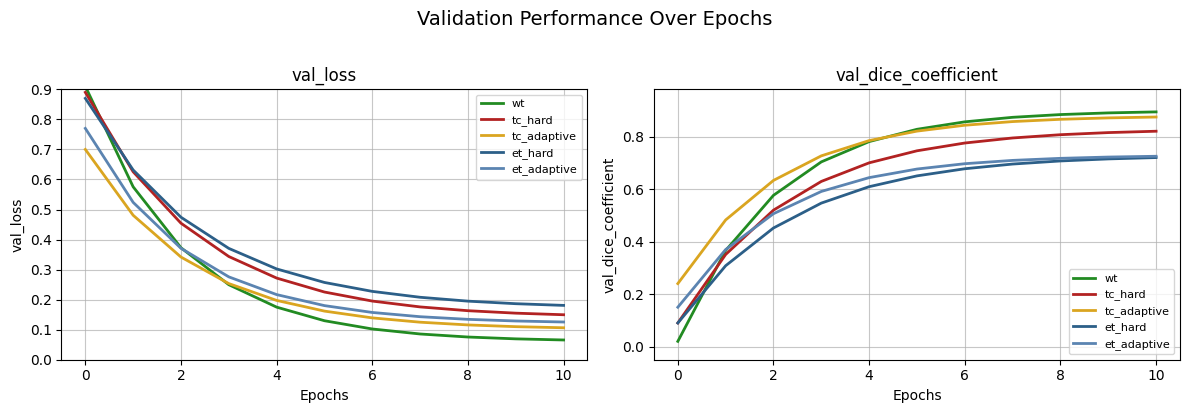

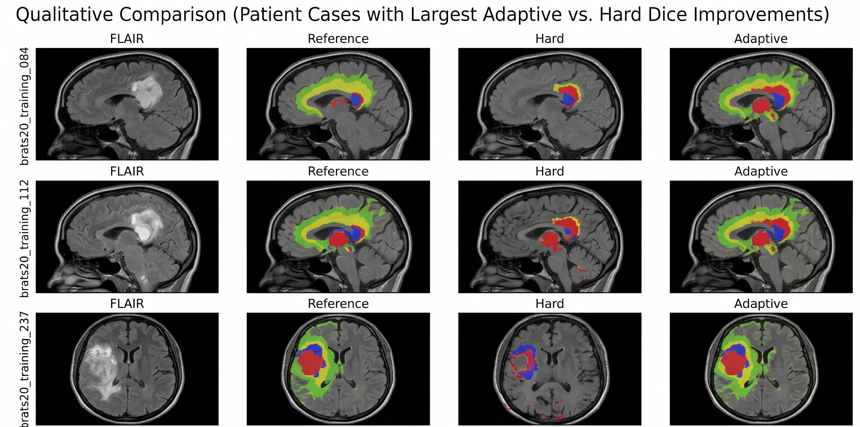

In [7]:
def plot_fold(folder):
    table = pd.read_csv(folder / "test_patients.csv")
    scores = table[table.region.isin(["tc", "et"])].pivot_table(index="patient", columns="mode", values="dice", aggfunc="sum")
    selected = (scores.adaptive - scores.hard).nlargest(3).index
    images = [patient_arrays(p) for p in selected]
    fig, axes = plt.subplots(len(selected), 4, figsize=(12, 3*len(selected)), squeeze=False)
    all_masks = {}
    for region, mode, stage in [("wt", "shared", "wt")] + [
        (r, m, f"{r}_{m}") for m in ["hard", "adaptive"] for r in ["tc", "et"]]:
        tf.keras.backend.clear_session()
        model = build_lcbts_subnetwork()
        model.load_weights(folder / stage / "best.weights.h5")
        outputs = []
        for i, (X, *_) in enumerate(images):
            if mode != "shared":
                X = X * guidance_maps(all_masks["wt", "shared"][i], mode)[0][...,None]
            outputs.append(model(X[None], training=False).numpy()[0,...,0])
        all_masks[region, mode] = outputs
        del model
    for i, (X, wt, tc, et) in enumerate(images):
        z = int(np.argmax(wt.sum(axis=(0,1))))
        bg = X[:,:,z,3]
        refs = [wt[:,:,z].astype(bool), tc[:,:,z].astype(bool), et[:,:,z].astype(bool)]
        panels = [bg, make_overlay(bg, *refs)]
        for mode in ["hard", "adaptive"]:
            masks = [all_masks[r,m][i][:,:,z] >= TAU for r,m in [("wt","shared"),("tc",mode),("et",mode)]]
            panels.append(make_overlay(bg, *masks))
        for ax, title, panel in zip(axes[i], ["FLAIR", "Reference", "Hard", "Adaptive"], panels):
            ax.imshow(np.swapaxes(panel,0,1), origin="lower", cmap="gray")
            ax.set_title(f"{selected[i]} · {title}", fontsize=8)
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(folder / "qualitative.png", dpi=160)
    plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    for log in sorted(folder.glob("*/training.csv")):
        history = pd.read_csv(log)
        for ax, metric in zip(axes, ["val_loss", "val_dice_coefficient"]):
            ax.plot(history.epoch+1, history[metric], label=log.parent.name)
            ax.set(xlabel="Epoch", ylabel=metric)
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(folder / "validation_curves.png", dpi=160)
    plt.show()

example = run / WT_LOSSES[0] / f"fold_{FOLDS[0]}"
if (example / "test_patients.csv").exists():
    plot_fold(example)


from IPython.display import Image, display

display(Image(filename="/kaggle/input/datasets/rudrapss/rabdom/Screenshot 2026-11-19 133231.png"))